# T1 Vision por computador Jose Quimi

Este archivo es para realizar los procesos paso a paso, posteriormente se arma un archivo main.py que ejecuta el codigo compelto por si solo

In [19]:
# imports
import os
import numpy as np
import matplotlib.pyplot as plt
import cv2

In [43]:
# imgs paths
img_path = os.path.join("..", "imgs")
# print(os.path.join(img_path, "img1.jpg"))
img1, img2, img3, img4 = [cv2.imread(os.path.join(img_path, f"img{i}.jpg")) for i in range(1, 5)]
N, M = img1.shape[:2] # eliminando el canal de color

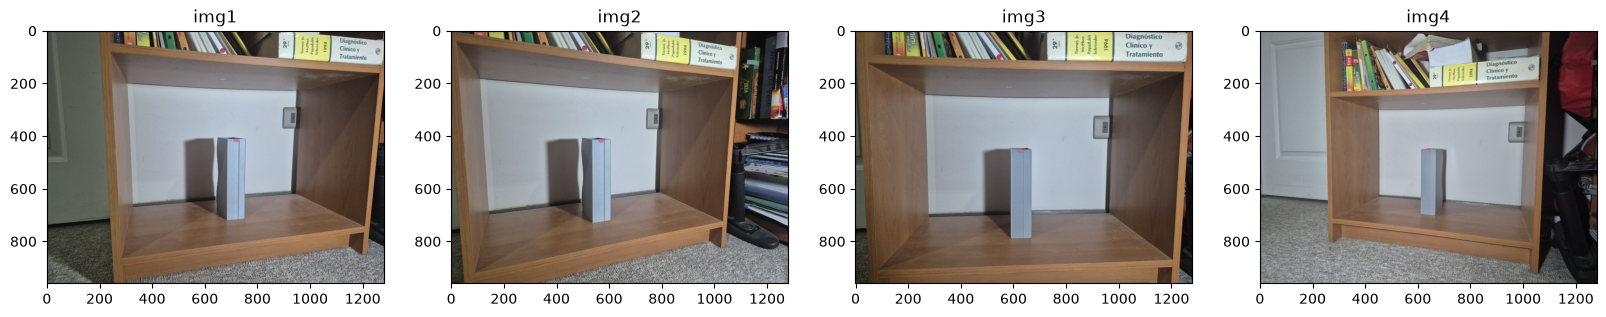

Shape = (960, 1280, 3)


In [21]:
# show imgs
fig, axs = plt.subplots(1, 4, figsize=(20, 10))
axs[0].imshow(cv2.cvtColor(img1, cv2.COLOR_BGR2RGB), cmap='gray')
axs[0].set_title('img1')

axs[1].imshow(cv2.cvtColor(img2, cv2.COLOR_BGR2RGB), cmap='gray')
axs[1].set_title('img2')

axs[2].imshow(cv2.cvtColor(img3, cv2.COLOR_BGR2RGB), cmap='gray')
axs[2].set_title('img3')

axs[3].imshow(cv2.cvtColor(img4, cv2.COLOR_BGR2RGB), cmap='gray')
axs[3].set_title('img4')
plt.show()
print(f"Shape = {img1.shape}")

Utilizando la imagen 3 como imagen explicativa, los puntos se disponen en el siguiente orden, siendo el punto 1 el punto de origen, ademas se indica el punto objetivo.

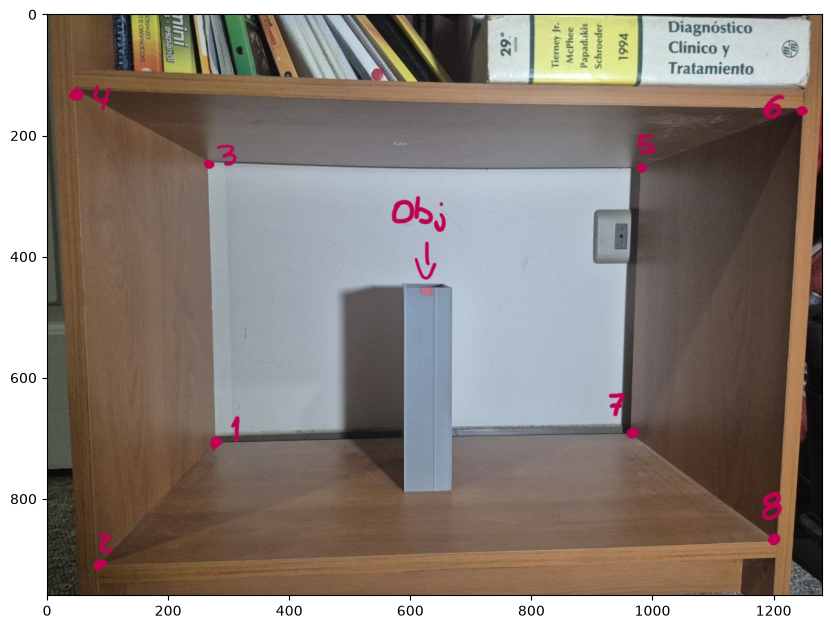

In [22]:
img_ej_path = os.path.join("..", "imgs/img_explicacion.jpg")
img_ej = cv2.imread(img_ej_path)
plt.figure(figsize=(10, 10))
plt.imshow(cv2.cvtColor(img_ej, cv2.COLOR_BGR2RGB), cmap='gray')
plt.show()

#### Obtener la matriz de calibracion de todas las imagenes

In [51]:
# definir M, los puntos reales con el punto 1 como el origen, todo en milimetros
M = np.array([
    [0.0,  0.0,   0.0,   0.0,   570.0, 570.0, 570.0, 570.0],
    [0.0,  294.0, 0.0,   294.0, 0.0,   294.0, 0.0,   294.0],
    [0.0,  0.0,   369.0, 369.0, 369.0, 369.0, 0.0,   0.0],
    [1.0,  1.0,   1.0,   1.0,   1.0,   1.0,   1.0,   1.0]
])
# lista de puntos
puntos_list_1 = []
puntos_list_2 = []
puntos_list_3 = []
puntos_list_4 = []

##### Funciones

In [52]:
# Funcion de calibracion de la camara
def calibracion(M,w):

  # Escribe código aquí
  n = M.shape[1]

  X_v = []

  for i in range(n):
    X, Y, Z = M[0, i], M[1, i], M[2, i]
    u, v = w[0, i], w[1, i]

    x_1 = np.array([X, Y, Z, 1, 0, 0, 0, 0, -u*X, -u*Y, -u*Z, -u])
    x_2 = np.array([0, 0, 0, 0, X, Y, Z, 1, -v*X, -v*Y, -v*Z, -v])

    # Apilar
    X_vi = np.vstack([x_1, x_2])

    if i == 0:
      X_v = X_vi
    else:
      X_v = np.vstack([X_v, X_vi])

  U, S, VT = np.linalg.svd(X_v)
  a = VT[-1,:]
  P = a.reshape(3, 4)

  return P
# Callback para mouse
def mouse_callback(event, x, y, flags, param):
    puntos_list, img = param
    if event == cv2.EVENT_LBUTTONDOWN:
        print(f"Clicked at: ({x}, {y})")
        puntos_list.append((x, y))
        
        cv2.circle(img, (x, y), 5, (0, 255, 0), -1)
        cv2.putText(img, f"{len(puntos_list)}", (x + 10, y - 10), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 0), 1)
    elif event == cv2.EVENT_RBUTTONDOWN:
        if puntos_list:
            punto_removido = puntos_list.pop()
            print(f"Punto removido {punto_removido}")
        img[:] = img.copy()
        
        for index, (px, py) in enumerate(puntos_list):
            cv2.circle(img, (px, py), 5, (0, 255, 0), -1)
            cv2.putText(img, f"{index + 1}", (px + 10, py - 10), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 0), 1)
            
# def obtener calibracion de imagen
def get_calibration(img, puntos_list):
    # levantar imagen y mostrarla en una ventana para obtener los puntos de las esquinas
    display_img = img.copy()
    flag = True
    cv2.namedWindow("Seleccionar puntos", cv2.WINDOW_NORMAL)
    # cv2.resizeWindow("Seleccionar puntos", img.shape[1], img.shape[0])
    cv2.setMouseCallback("Seleccionar puntos", mouse_callback, param=(puntos_list, display_img))

    while flag:
        cv2.imshow("Seleccionar puntos", display_img)
        key = cv2.waitKey(1) & 0xFF

        if key == ord('q'):
            flag = False
        elif key == ord('r'):
            puntos_list.clear()
            display_img = img.copy()
            print("Puntos reiniciados")
    cv2.destroyAllWindows()
    print(f"Puntos seleccionados: {puntos_list}")
    x, y = zip(*puntos_list)

    plt.figure(figsize=(10, 10))

    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB), cmap='gray')
    plt.scatter(x, y, color='red', s=15)
    plt.show()
    print(f"Los puntos que representan la caja son: {puntos_list}")
    # obtener matriz de proyeccion P

    # Definir los vectores de m1
    x_p = np.array([p[0] for p in puntos_list])
    y_p = np.array([p[1] for p in puntos_list])
    print(f"x_p = {x_p}")
    print(f"y_p = {y_p}")

    m1 = np.vstack((x_p, y_p, np.ones(len(x_p))))
    print(m1)

    P = calibracion(M, m1)
    print(f"Matriz de proyeccion P = \n{P}")
    return (P, puntos_list)

def get_m1_mouse_callback(event, x, y, flags, param):
    state= param
    if event == cv2.EVENT_LBUTTONDOWN:
        print(f"Clicked at: ({x}, {y})")
        state['m1'] = np.array([x, y, 1])
        
        cv2.circle(state['display_img'], (x, y), 5, (0, 255, 0), -1)
        cv2.putText(state['display_img'], f"m1", (x + 10, y - 10), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 0), 1)
    elif event == cv2.EVENT_RBUTTONDOWN:
        state['m1'] = None
        state['display_img'][:] = state['img_o'].copy()
        
def get_m1(img):
    """Esta funcion es el unico input del sistema, saca el punto rojo de la caja por medio del mouse y devuelve m1"""
    flag = True
    display_img = img.copy()
    state = {'m1': None,
             'display_img': display_img,
             'img_o': img.copy()}
    cv2.namedWindow("Seleccionar punto rojo", cv2.WINDOW_NORMAL)
    # cv2.resizeWindow("Seleccionar punto rojo", display_img.shape[1], display_img.shape[0])
    cv2.setMouseCallback("Seleccionar punto rojo", get_m1_mouse_callback, param=state)
    while flag:
        cv2.imshow("Seleccionar punto rojo", display_img)
        key = cv2.waitKey(1) & 0xFF

        if key == ord('q'):
            flag = False
        elif key == ord('r'):
            state['m1'] = None
            state['display_img'] = state['img_o'].copy()
            print("Puntos reiniciados")
    cv2.destroyAllWindows()
    return state['m1']
    
    
    

Clicked at: (327, 668)
Clicked at: (285, 867)
Clicked at: (307, 199)
Clicked at: (244, 82)
Clicked at: (966, 228)
Clicked at: (1263, 162)
Clicked at: (947, 617)
Clicked at: (1207, 743)
Puntos seleccionados: [(327, 668), (285, 867), (307, 199), (244, 82), (966, 228), (1263, 162), (947, 617), (1207, 743)]


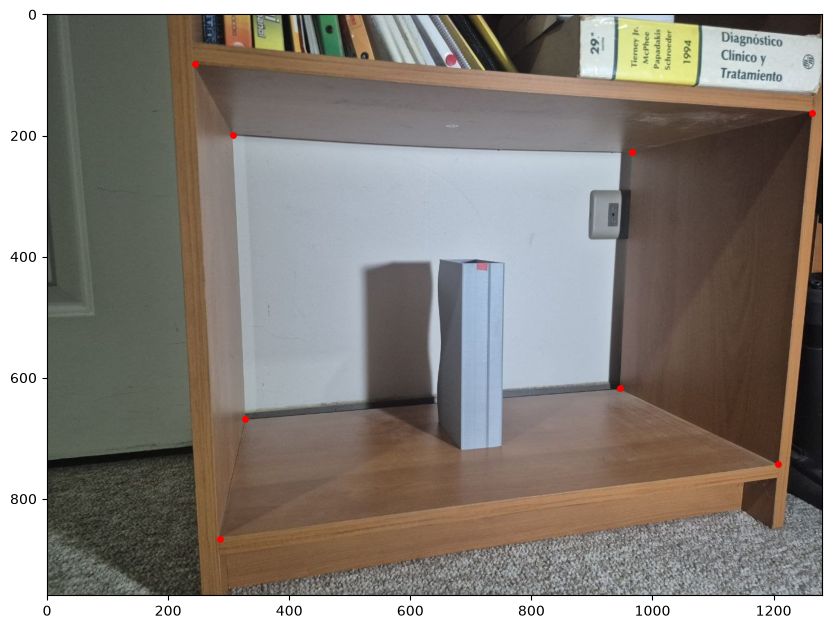

Los puntos que representan la caja son: [(327, 668), (285, 867), (307, 199), (244, 82), (966, 228), (1263, 162), (947, 617), (1207, 743)]
x_p = [ 327  285  307  244  966 1263  947 1207]
y_p = [668 867 199  82 228 162 617 743]
[[3.270e+02 2.850e+02 3.070e+02 2.440e+02 9.660e+02 1.263e+03 9.470e+02
  1.207e+03]
 [6.680e+02 8.670e+02 1.990e+02 8.200e+01 2.280e+02 1.620e+02 6.170e+02
  7.430e+02]
 [1.000e+00 1.000e+00 1.000e+00 1.000e+00 1.000e+00 1.000e+00 1.000e+00
  1.000e+00]]
Matriz de proyeccion P = 
[[ 1.91316075e-03 -7.03060598e-04 -1.51288745e-04  4.40190655e-01]
 [ 1.77525842e-04 -6.32472011e-04 -1.76319773e-03  8.97899028e-01]
 [ 4.81663497e-07 -1.77550632e-06 -2.48449872e-07  1.34338607e-03]]
Clicked at: (145, 700)
Clicked at: (87, 919)
Punto removido (87, 919)
Clicked at: (90, 921)
Clicked at: (110, 183)
Clicked at: (19, 46)
Clicked at: (806, 235)
Clicked at: (1071, 178)
Clicked at: (792, 614)
Clicked at: (1031, 724)
Puntos seleccionados: [(145, 700), (90, 921), (110, 183), (1

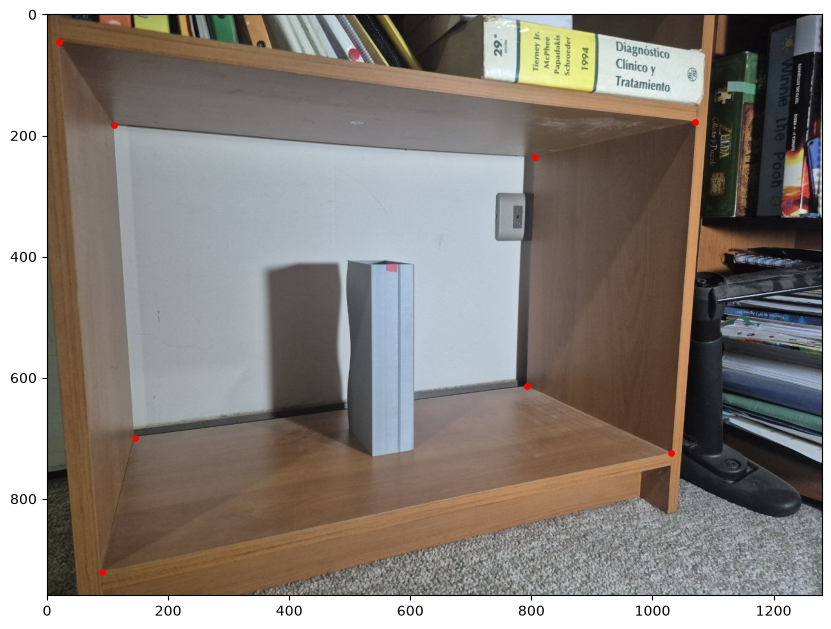

Los puntos que representan la caja son: [(145, 700), (90, 921), (110, 183), (19, 46), (806, 235), (1071, 178), (792, 614), (1031, 724)]
x_p = [ 145   90  110   19  806 1071  792 1031]
y_p = [700 921 183  46 235 178 614 724]
[[1.450e+02 9.000e+01 1.100e+02 1.900e+01 8.060e+02 1.071e+03 7.920e+02
  1.031e+03]
 [7.000e+02 9.210e+02 1.830e+02 4.600e+01 2.350e+02 1.780e+02 6.140e+02
  7.240e+02]
 [1.000e+00 1.000e+00 1.000e+00 1.000e+00 1.000e+00 1.000e+00 1.000e+00
  1.000e+00]]
Matriz de proyeccion P = 
[[ 2.26580783e-03 -4.34458662e-04 -1.66397264e-04  2.03401035e-01]
 [ 3.18758162e-04 -6.87249922e-04 -2.01221807e-03  9.79089414e-01]
 [ 8.50645766e-07 -1.90516320e-06 -2.92139233e-07  1.40191314e-03]]
Clicked at: (279, 707)
Clicked at: (85, 909)
Clicked at: (267, 243)
Clicked at: (46, 124)
Clicked at: (979, 252)
Clicked at: (1246, 156)
Clicked at: (962, 692)
Clicked at: (1205, 872)
Punto removido (1205, 872)
Clicked at: (1203, 870)
Puntos seleccionados: [(279, 707), (85, 909), (267, 243),

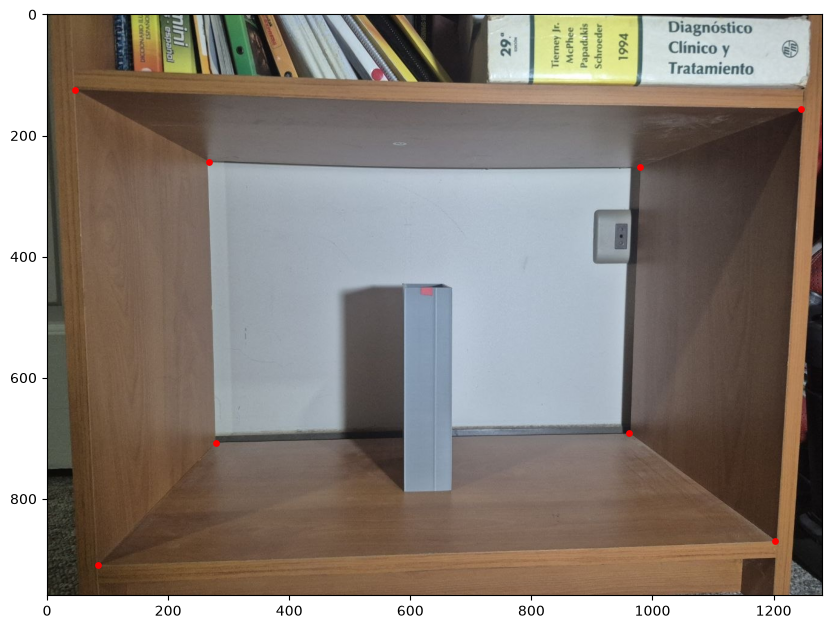

Los puntos que representan la caja son: [(279, 707), (85, 909), (267, 243), (46, 124), (979, 252), (1246, 156), (962, 692), (1203, 870)]
x_p = [ 279   85  267   46  979 1246  962 1203]
y_p = [707 909 243 124 252 156 692 870]
[[2.790e+02 8.500e+01 2.670e+02 4.600e+01 9.790e+02 1.246e+03 9.620e+02
  1.203e+03]
 [7.070e+02 9.090e+02 2.430e+02 1.240e+02 2.520e+02 1.560e+02 6.920e+02
  8.700e+02]
 [1.000e+00 1.000e+00 1.000e+00 1.000e+00 1.000e+00 1.000e+00 1.000e+00
  1.000e+00]]
Matriz de proyeccion P = 
[[ 1.70162599e-03 -1.02516987e-03 -8.70594559e-05  3.67814161e-01]
 [ 5.70864508e-05 -7.24891683e-04 -1.69357253e-03  9.29894435e-01]
 [ 1.29915524e-07 -1.79695580e-06 -1.52341416e-07  1.31610970e-03]]
Clicked at: (453, 629)
Clicked at: (276, 711)
Clicked at: (450, 304)
Clicked at: (268, 252)
Clicked at: (1008, 284)
Clicked at: (1063, 216)
Clicked at: (990, 675)
Clicked at: (1036, 805)
Puntos seleccionados: [(453, 629), (276, 711), (450, 304), (268, 252), (1008, 284), (1063, 216), (990, 6

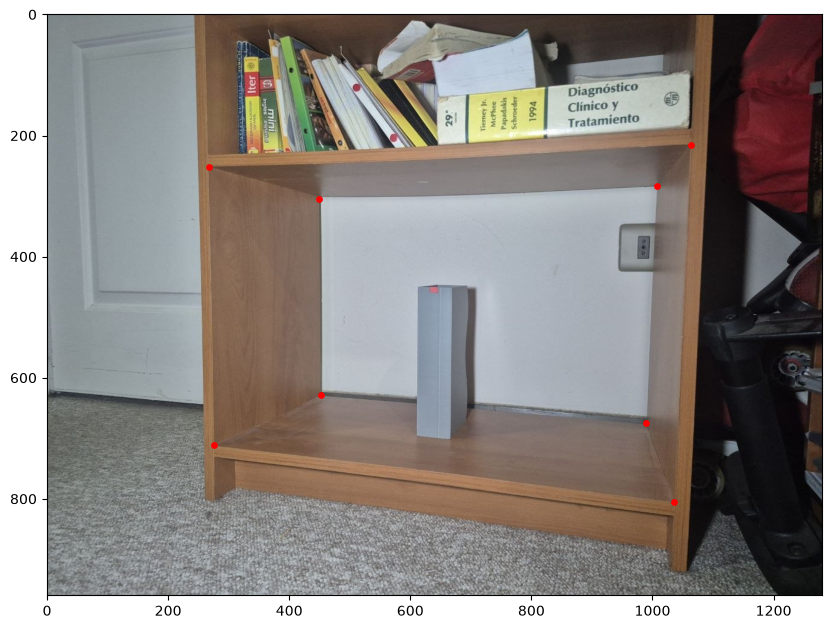

Los puntos que representan la caja son: [(453, 629), (276, 711), (450, 304), (268, 252), (1008, 284), (1063, 216), (990, 675), (1036, 805)]
x_p = [ 453  276  450  268 1008 1063  990 1036]
y_p = [629 711 304 252 284 216 675 805]
[[4.530e+02 2.760e+02 4.500e+02 2.680e+02 1.008e+03 1.063e+03 9.900e+02
  1.036e+03]
 [6.290e+02 7.110e+02 3.040e+02 2.520e+02 2.840e+02 2.160e+02 6.750e+02
  8.050e+02]
 [1.000e+00 1.000e+00 1.000e+00 1.000e+00 1.000e+00 1.000e+00 1.000e+00
  1.000e+00]]
Matriz de proyeccion P = 
[[ 8.57928909e-04 -1.11398037e-03 -4.98097287e-05  5.83847574e-01]
 [-1.40876678e-04 -5.19541180e-04 -1.17252546e-03  8.11860025e-01]
 [-3.63757383e-07 -1.23640745e-06 -9.82858324e-08  1.29052271e-03]]


In [53]:
P1, puntos_list_1 = get_calibration(img1, puntos_list_1)
P2, puntos_list_2 = get_calibration(img2, puntos_list_2)
P3, puntos_list_3 = get_calibration(img3, puntos_list_3)
P4, puntos_list_4 = get_calibration(img4, puntos_list_4)

In [54]:
# mostrar los puntos para mantener el registro manualmente
print("Puntos seleccionados en las imagenes:")
print(f"Puntos primera imagen m1: {puntos_list_1}")
print(f"Puntos segunda imagen m2: {puntos_list_2}")
print(f"Puntos tercera imagen m3: {puntos_list_3}")
print(f"Puntos cuarta imagen m4: {puntos_list_4}")

Puntos seleccionados en las imagenes:
Puntos primera imagen m1: [(327, 668), (285, 867), (307, 199), (244, 82), (966, 228), (1263, 162), (947, 617), (1207, 743)]
Puntos segunda imagen m2: [(145, 700), (90, 921), (110, 183), (19, 46), (806, 235), (1071, 178), (792, 614), (1031, 724)]
Puntos tercera imagen m3: [(279, 707), (85, 909), (267, 243), (46, 124), (979, 252), (1246, 156), (962, 692), (1203, 870)]
Puntos cuarta imagen m4: [(453, 629), (276, 711), (450, 304), (268, 252), (1008, 284), (1063, 216), (990, 675), (1036, 805)]


##### Obtener m1 de la imagen 1

Clicked at: (719, 417)
El punto rojo m1 es: [719 417   1]


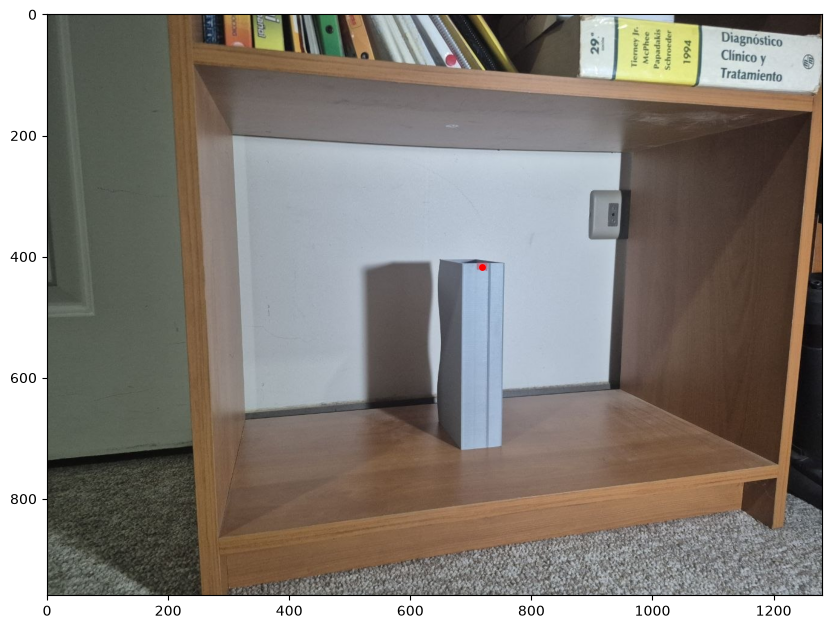

In [55]:
m1 = get_m1(img1)
print(f"El punto rojo m1 es: {m1}")
# print(f"m1: {m1[0]}, {m1[1]}")
plt.figure(figsize=(10, 10))
plt.imshow(cv2.cvtColor(img1, cv2.COLOR_BGR2RGB), cmap='gray')
plt.scatter(m1[0], m1[1], color='red', s=15)
plt.show()

#### Realizar homografia desde img 1 a img2

In [56]:
# Extraido de E02
def homography(X,H):
  N, M, C = X.shape
  Hinv  = np.linalg.inv(H)
  Xp    = np.zeros((N,M,C),np.uint8)

  m = np.ones((N*M,3))
  t = 0
  for i in range(N):
    for j in range(M):
      m[t,0:2] = [j,i]
      t = t+1

  mph = np.dot(Hinv,m.T)  # Transformation m to mp
  mp  = np.divide(mph[0:2,:],mph[2,:])
  mpf = np.trunc(mp).astype(int) #np.fix is deprecated

  ip = mpf[1,:]
  jp = mpf[0,:]
  
  ktj = np.logical_and(jp >= 0,  jp<M)
  kti = np.logical_and(ip >=0, ip < N)
  kt  = np.logical_and(kti, ktj)

  t = 0
  for i in range(N):
    for j in range(M):
      if kt[t]:
        Xp[i,j] = X[ip[t],jp[t]]
      t = t+1
  return Xp

def homography_matrix(m,mp):
  (x ,y ) = m
  (xp,yp) = mp
  n       = len(x)
  A       = np.zeros((2*n,9))
  for i in range(n):
    j = i*2
    A[j  ,:] = [x[i], y[i], 1,     0,     0, 0, -x[i]*xp[i], -y[i]*xp[i], -xp[i]]
    A[j+1,:] = [  0  ,   0  , 0, x[i], y[i], 1, -x[i]*yp[i], -y[i]*yp[i], -yp[i]]
  [U,S,V] = np.linalg.svd(A)
  h       = V[-1,:]
  H       = np.vstack([h[0:3], h[3:6], h[6:9]])
  return H

def homography_with_calibration(P1, P2):
  H = None
  # obtener submatrices de P1 y P2 usando descomposicion RQ Szeliski
  M1 = P1[:, :3] # como P1 y P2 son con el mismo centro optico, la traslacion (t) es 0, K es igual porque es la misma camara y centro optico es 0
  M2 = P2[:, :3] # como P1 y P2 son con el mismo centro optico, la traslacion (t) es 0, K es igual porque es la misma camara y centro optico es 0
  # solo es diferente la rotacion.
  M_intercambiado_1 = M1[::-1, ::-1]
  K_temp, R_temp = np.linalg.qr(M_intercambiado_1.T) #usando la qr de numpy
  
  M_intercambiado_2 = M2[::-1, ::-1]
  K_temp2, R_temp2 = np.linalg.qr(M_intercambiado_2.T) 
  #reconstruir K y R a partir de las submatrices obtenidas
  K_1 = R_temp.T[::-1, ::-1]
  R_r1 = K_temp.T[::-1, ::-1]
  K_2 = R_temp2.T[::-1, ::-1]
  R_r2 = K_temp2.T[::-1, ::-1]

  #correccion de signos
  T1 = np.diag(np.sign(np.diag(K_1)))
  K1 = K_1 @ T1
  R1 = T1 @ R_r1
  
  T2 = np.diag(np.sign(np.diag(K_2)))
  K2 = K_2 @ T2
  R2 = T2 @ R_r2
  
  #normalizacion homogenea
  K1 = K1 / K1[2, 2] # esto fuerza que el ultimo elemento sea 1
  K2 = K2 / K2[2, 2]
  
  # Rotacion relativa
  R = R2 @ R1.T
  
  # armar matriz de homografia
  H = K2 @ R @ np.linalg.inv(K1)
  
  return H
        

In [57]:
# obtener matriz de homografia
H = homography_with_calibration(P1, P2)
print(f"Matriz de homografia H = \n{H}")

Matriz de homografia H = 
[[ 1.09874605e+00  2.08503645e-02 -2.26895137e+02]
 [ 6.42162526e-02  1.00609929e+00 -4.27566414e+01]
 [ 1.70737596e-04  8.04706340e-06  8.75009911e-01]]


## Obtener m2 a partir de la homografia

El punto rojo m2 es: [571.79787355 422.95824932   1.00112587]


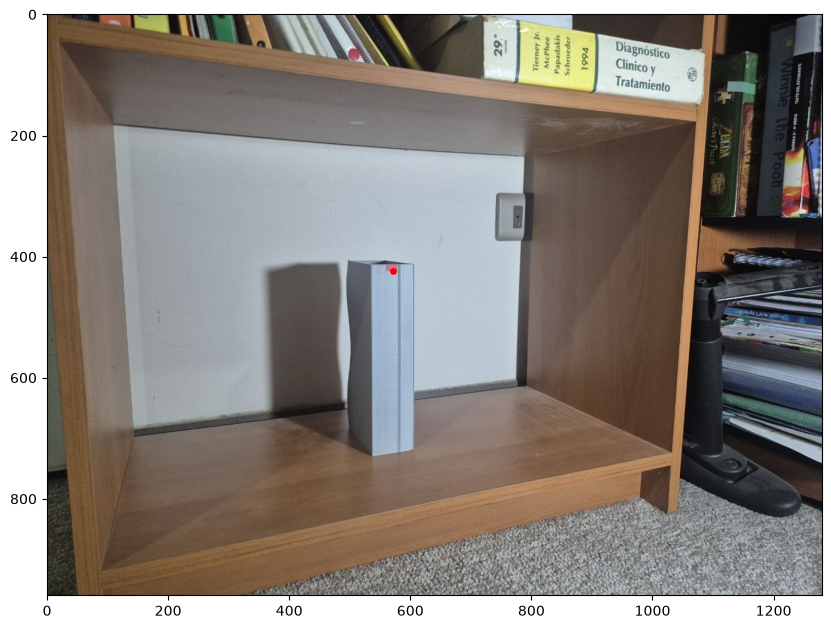

In [58]:
m2 = H @ m1
print(f"El punto rojo m2 es: {m2}")
plt.figure(figsize=(10, 10))
plt.imshow(cv2.cvtColor(img2, cv2.COLOR_BGR2RGB), cmap='gray')
plt.scatter(m2[0], m2[1], color='red', s=15)
plt.show()